In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report



In [3]:
df = pd.read_csv("Titanic.csv")

In [5]:
 df.shape

(891, 12)

In [7]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [13]:
 df_raw["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [26]:
df = df_raw.copy()
df["Age"] = df["Age"].fillna(df["Age"].median())
most_common_port = df["Embarked"].mode()[0]
df["Embarked"] = df["Embarked"].fillna(most_common_port)
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
df = pd.get_dummies(df, columns=["Embarked"], drop_first=True, dtype=int)
features = ["Survived", "Pclass", "Sex", "Age", "Fare", "Embarked_Q", "Embarked_S"]
df_cleaned = df[features]
print("Missing values after cleaning:\n", df_cleaned.isna().sum().sum())
print("\nCleaned preview:\n", df_cleaned.head())


Missing values after cleaning:
 0

Cleaned preview:
    Survived  Pclass  Sex   Age     Fare  Embarked_Q  Embarked_S
0         0       3    0  22.0   7.2500           0           1
1         1       1    1  38.0  71.2833           0           0
2         1       3    1  26.0   7.9250           0           1
3         1       1    1  35.0  53.1000           0           1
4         0       3    0  35.0   8.0500           0           1


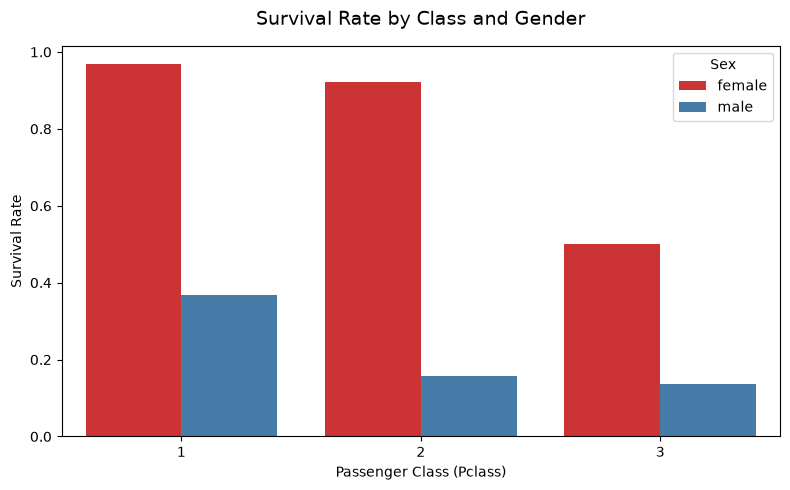

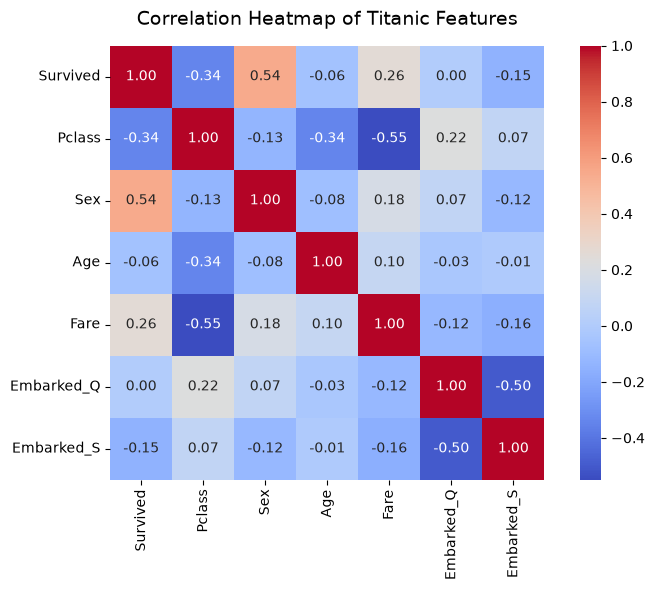

In [27]:
# Figure 1: Breakdown of Survival Rates by Class and Gender
plt.figure(figsize=(8, 5))
sns.barplot(data=df_raw, x="Pclass", y="Survived", hue="Sex", errorbar=None, palette="Set1")
plt.title("Survival Rate by Class and Gender", fontsize=14, pad=15)
plt.xlabel("Passenger Class (Pclass)")
plt.ylabel("Survival Rate")
plt.tight_layout()
plt.show()

# Figure 2: Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df_cleaned.corr(), annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True)
plt.title("Correlation Heatmap of Titanic Features", fontsize=14, pad=15)
plt.tight_layout()
plt.show()


In [30]:
X = df_cleaned.drop(columns=["Survived"])
y = df_cleaned["Survived"]

# Change 'test_test_split' to 'test_size'
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [31]:
lr_model = LogisticRegression(max_iter=500, random_state=42)
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

print("=" * 45)
print("Logistic Regression Metrics")
print("=" * 45)
print(f"Accuracy: {accuracy_score(y_test, lr_preds):.4f}")
print("Confusion Matrix:\n", confusion_matrix(y_test, lr_preds))
print("\nClassification Report:\n", classification_report(y_test, lr_preds, target_names=["Died", "Survived"]))


Logistic Regression Metrics
Accuracy: 0.7989
Confusion Matrix:
 [[88 17]
 [19 55]]

Classification Report:
               precision    recall  f1-score   support

        Died       0.82      0.84      0.83       105
    Survived       0.76      0.74      0.75        74

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



In [32]:
rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

print("=" * 45)
print("Random Forest Metrics")
print("=" * 45)
print(f"Accuracy: {accuracy_score(y_test, rf_preds):.4f}")
print("Confusion Matrix:\n", confusion_matrix(y_test, rf_preds))
print("\nClassification Report:\n", classification_report(y_test, rf_preds, target_names=["Died", "Survived"]))

Random Forest Metrics
Accuracy: 0.7877
Confusion Matrix:
 [[85 20]
 [18 56]]

Classification Report:
               precision    recall  f1-score   support

        Died       0.83      0.81      0.82       105
    Survived       0.74      0.76      0.75        74

    accuracy                           0.79       179
   macro avg       0.78      0.78      0.78       179
weighted avg       0.79      0.79      0.79       179



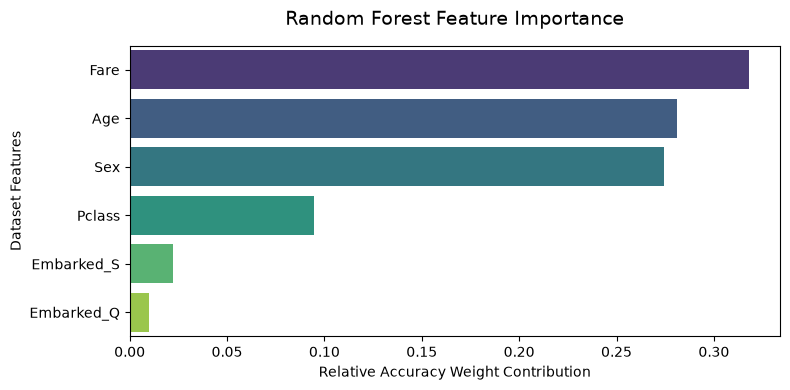

In [33]:

importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)
plt.figure(figsize=(8, 4))
sns.barplot(data=importances, x='Importance', y='Feature', hue='Feature', palette='viridis', legend=False)
plt.title("Random Forest Feature Importance", fontsize=14, pad=15)
plt.xlabel("Relative Accuracy Weight Contribution")
plt.ylabel("Dataset Features")
plt.tight_layout()
plt.show()
